In [12]:
import sys
from pathlib import Path

# Encontra o módulo e disponibiliza seu pacote Python, sem depender da pasta atual.
PASTA_ATUAL = Path.cwd().resolve()
PASTA_PROJETO = next(
    (
        pasta
        for base in (PASTA_ATUAL, *PASTA_ATUAL.parents)
        for pasta in (
            base,
            base / "04_regressao_polinomial",
            base / "regressao_modelos_lineares" / "04_regressao_polinomial",
        )
        if (pasta / "src" / "polinomial" / "config.py").is_file()
    ),
    None,
)
if PASTA_PROJETO is None:
    raise FileNotFoundError("Não foi possível localizar o módulo 04_regressao_polinomial.")
PASTA_SRC = PASTA_PROJETO / "src"
if str(PASTA_SRC) not in sys.path:
    sys.path.insert(0, str(PASTA_SRC))

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import ElasticNet, LinearRegression
from sklearn.preprocessing import (
    OrdinalEncoder,
    OneHotEncoder,
    PolynomialFeatures,
    PowerTransformer,
    StandardScaler,
    QuantileTransformer,
)

from polinomial.auxiliares import dataframe_coeficientes
from polinomial.config import DADOS_DIABETES_CATEGORIZADOS
from polinomial.graficos import plot_comparar_metricas_modelos, plot_coeficientes
from polinomial.modelos import RANDOM_STATE
from polinomial.modelos import grid_search_cv_regressor, organiza_resultados, treinar_e_validar_modelo_regressao

sns.set_theme(palette="bright")

In [13]:
df = pd.read_parquet(DADOS_DIABETES_CATEGORIZADOS)

df.head()

,idade,sexo,imc,pressao_media,colesterol_total,ldl,hdl,triglicerides,glicose,target,colesterol_hdl_cat
0,59,2,32.099998,101.0,157,93.199997,38.0,4.8598,87,151,4-5
1,48,1,21.600000,87.0,183,103.199997,70.0,3.8918,69,75,2-3
2,72,2,30.500000,93.0,156,93.599998,41.0,4.6728,85,141,4-5
3,24,1,25.299999,84.0,198,131.399994,40.0,4.8903,89,206,4-5
4,50,1,23.000000,101.0,192,125.400002,52.0,4.2905,80,135,4-5


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   idade               442 non-null    int8    
 1   sexo                442 non-null    int8    
 2   imc                 442 non-null    float32 
 3   pressao_media       442 non-null    float32 
 4   colesterol_total    442 non-null    int16   
 5   ldl                 442 non-null    float32 
 6   hdl                 442 non-null    float32 
 7   triglicerides       442 non-null    float32 
 8   glicose             442 non-null    int8    
 9   target              442 non-null    int16   
 10  colesterol_hdl_cat  442 non-null    category
dtypes: category(1), float32(5), int16(2), int8(3)
memory usage: 12.3 KB


In [15]:
X = df.drop(columns="target")
y = df["target"]

In [16]:
colunas_power_transform = ["imc", "ldl", "hdl", "colesterol_total"]

coluna_target = ["target"]

coluna_ordinal_encoder = ["colesterol_hdl_cat"]

coluna_one_hot_encoder = ["sexo"]

colunas_standard_scaler = [
    coluna
    for coluna in df.columns
    if coluna not in colunas_power_transform + coluna_target + coluna_ordinal_encoder + coluna_one_hot_encoder
]

colunas_standard_scaler

['idade', 'pressao_media', 'triglicerides', 'glicose']

In [17]:
categorias_ordinal_encoder = [
    ["2-3", "4-5", "6+"],
]

In [18]:
preprocessamento_categoricas = ColumnTransformer(
    transformers=[
        ("ordinal_encoder", OrdinalEncoder(categories=categorias_ordinal_encoder), coluna_ordinal_encoder),
        ("one_hot_encoder", OneHotEncoder(drop="if_binary"), coluna_one_hot_encoder),
    ],
    remainder="passthrough",
)

preprocessamento_simples = ColumnTransformer(
    transformers=[
        ("ordinal_encoder", OrdinalEncoder(categories=categorias_ordinal_encoder), coluna_ordinal_encoder),
        ("one_hot_encoder", OneHotEncoder(drop="if_binary"), coluna_one_hot_encoder),
        ("standard_scaler", StandardScaler(), X.columns.difference(coluna_ordinal_encoder + coluna_one_hot_encoder)),
    ],
    remainder="passthrough",
)

preprocessamento_completo = ColumnTransformer(
    [
        ("power_transform", PowerTransformer(method="box-cox"), colunas_power_transform),
        ("standard_scaler", StandardScaler(), colunas_standard_scaler),
        ("ordinal_encoder", OrdinalEncoder(categories=categorias_ordinal_encoder), coluna_ordinal_encoder),
        ("one_hot_encoder", OneHotEncoder(drop="if_binary"), coluna_one_hot_encoder),
    ]
)

target_transformer = QuantileTransformer(n_quantiles=20, output_distribution="normal")

In [19]:
elasticnet_regressor = ElasticNet()

In [20]:
param_grid = {
    "regressor__reg__alpha": [1E-2, 5E-2, 0.1, 1.0, 5.0, 10],
    "regressor__reg__l1_ratio": [0.1, 0.25, 0.5, 0.75, 0.9],
    "regressor__preprocessor": [preprocessamento_categoricas, preprocessamento_simples, preprocessamento_completo],
    "transformer": [target_transformer, None]
}

In [21]:
grid_search = grid_search_cv_regressor(
    regressor=elasticnet_regressor,
    param_grid=param_grid,
    preprocessor=preprocessamento_categoricas,
    target_transformer=target_transformer,
)

grid_search

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             error_score='raise',
             estimator=TransformedTargetRegressor(regressor=Pipeline(steps=[('preprocessor',
                                                                             ColumnTransformer(remainder='passthrough',
                                                                                               transformers=[('ordinal_encoder',
                                                                                                              OrdinalEncoder(categories=[['2-3',
                                                                                                                                          '4-5',
                                                                                                                                          '6+']]),
                                                                                                              ['colesterol_hdl_cat']),
                                                                                                             ('one_hot_encoder',
                                                                                                              OneHotEncoder(drop='if...
                                                                                      OneHotEncoder(drop='if_binary'),
                                                                                      ['sexo'])])],
                         'regressor__reg__alpha': [0.01, 0.05, 0.1, 1.0, 5.0,
                                                   10],
                         'regressor__reg__l1_ratio': [0.1, 0.25, 0.5, 0.75,
                                                      0.9],
                         'transformer': [QuantileTransformer(n_quantiles=20,
                                                             output_distribution='normal'),
                                         None]},
             refit='neg_root_mean_squared_error',
             scoring=['r2', 'neg_mean_absolute_error',
                      'neg_root_mean_squared_error'],
             verbose=1)

In [22]:
grid_search.fit(X, y)

Fitting 5 folds for each of 180 candidates, totalling 900 fits


GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             error_score='raise',
             estimator=TransformedTargetRegressor(regressor=Pipeline(steps=[('preprocessor',
                                                                             ColumnTransformer(remainder='passthrough',
                                                                                               transformers=[('ordinal_encoder',
                                                                                                              OrdinalEncoder(categories=[['2-3',
                                                                                                                                          '4-5',
                                                                                                                                          '6+']]),
                                                                                                              ['colesterol_hdl_cat']),
                                                                                                             ('one_hot_encoder',
                                                                                                              OneHotEncoder(drop='if...
                                                                                      OneHotEncoder(drop='if_binary'),
                                                                                      ['sexo'])])],
                         'regressor__reg__alpha': [0.01, 0.05, 0.1, 1.0, 5.0,
                                                   10],
                         'regressor__reg__l1_ratio': [0.1, 0.25, 0.5, 0.75,
                                                      0.9],
                         'transformer': [QuantileTransformer(n_quantiles=20,
                                                             output_distribution='normal'),
                                         None]},
             refit='neg_root_mean_squared_error',
             scoring=['r2', 'neg_mean_absolute_error',
                      'neg_root_mean_squared_error'],
             verbose=1)

In [23]:
grid_search.best_params_

{'regressor__preprocessor': ColumnTransformer(remainder='passthrough',
                   transformers=[('ordinal_encoder',
                                  OrdinalEncoder(categories=[['2-3', '4-5',
                                                              '6+']]),
                                  ['colesterol_hdl_cat']),
                                 ('one_hot_encoder',
                                  OneHotEncoder(drop='if_binary'), ['sexo']),
                                 ('standard_scaler', StandardScaler(),
                                  Index(['colesterol_total', 'glicose', 'hdl', 'idade', 'imc', 'ldl',
        'pressao_media', 'triglicerides'],
       dtype='object'))]),
 'regressor__reg__alpha': 0.01,
 'regressor__reg__l1_ratio': 0.9,
 'transformer': None}

In [24]:
grid_search.best_score_

-54.644797863944675

In [25]:
grid_search.best_estimator_

TransformedTargetRegressor(regressor=Pipeline(steps=[('preprocessor',
                                                      ColumnTransformer(remainder='passthrough',
                                                                        transformers=[('ordinal_encoder',
                                                                                       OrdinalEncoder(categories=[['2-3',
                                                                                                                   '4-5',
                                                                                                                   '6+']]),
                                                                                       ['colesterol_hdl_cat']),
                                                                                      ('one_hot_encoder',
                                                                                       OneHotEncoder(drop='if_binary'),
                                                                                       ['sexo']),
                                                                                      ('standard_scaler',
                                                                                       StandardScaler(),
                                                                                       Index(['colesterol_total', 'glicose', 'hdl', 'idade', 'imc', 'ldl',
       'pressao_media', 'triglicerides'],
      dtype='object'))])),
                                                     ('reg',
                                                      ElasticNet(alpha=0.01,
                                                                 l1_ratio=0.9))]))

In [26]:
print(*grid_search.cv_results_.keys(), sep="\n")

mean_fit_time
std_fit_time
mean_score_time
std_score_time
param_regressor__preprocessor
param_regressor__reg__alpha
param_regressor__reg__l1_ratio
param_transformer
params
split0_test_r2
split1_test_r2
split2_test_r2
split3_test_r2
split4_test_r2
mean_test_r2
std_test_r2
rank_test_r2
split0_test_neg_mean_absolute_error
split1_test_neg_mean_absolute_error
split2_test_neg_mean_absolute_error
split3_test_neg_mean_absolute_error
split4_test_neg_mean_absolute_error
mean_test_neg_mean_absolute_error
std_test_neg_mean_absolute_error
rank_test_neg_mean_absolute_error
split0_test_neg_root_mean_squared_error
split1_test_neg_root_mean_squared_error
split2_test_neg_root_mean_squared_error
split3_test_neg_root_mean_squared_error
split4_test_neg_root_mean_squared_error
mean_test_neg_root_mean_squared_error
std_test_neg_root_mean_squared_error
rank_test_neg_root_mean_squared_error


In [27]:
max(grid_search.cv_results_["mean_test_neg_root_mean_squared_error"])

-54.644797863944675

In [28]:
grid_search.best_estimator_

TransformedTargetRegressor(regressor=Pipeline(steps=[('preprocessor',
                                                      ColumnTransformer(remainder='passthrough',
                                                                        transformers=[('ordinal_encoder',
                                                                                       OrdinalEncoder(categories=[['2-3',
                                                                                                                   '4-5',
                                                                                                                   '6+']]),
                                                                                       ['colesterol_hdl_cat']),
                                                                                      ('one_hot_encoder',
                                                                                       OneHotEncoder(drop='if_binary'),
                                                                                       ['sexo']),
                                                                                      ('standard_scaler',
                                                                                       StandardScaler(),
                                                                                       Index(['colesterol_total', 'glicose', 'hdl', 'idade', 'imc', 'ldl',
       'pressao_media', 'triglicerides'],
      dtype='object'))])),
                                                     ('reg',
                                                      ElasticNet(alpha=0.01,
                                                                 l1_ratio=0.9))]))

In [29]:
grid_search.best_estimator_.regressor_["preprocessor"]

ColumnTransformer(remainder='passthrough',
                  transformers=[('ordinal_encoder',
                                 OrdinalEncoder(categories=[['2-3', '4-5',
                                                             '6+']]),
                                 ['colesterol_hdl_cat']),
                                ('one_hot_encoder',
                                 OneHotEncoder(drop='if_binary'), ['sexo']),
                                ('standard_scaler', StandardScaler(),
                                 Index(['colesterol_total', 'glicose', 'hdl', 'idade', 'imc', 'ldl',
       'pressao_media', 'triglicerides'],
      dtype='object'))])

In [30]:
grid_search.best_estimator_.regressor_["reg"]

ElasticNet(alpha=0.01, l1_ratio=0.9)

In [31]:
grid_search.best_estimator_.transformer_

FunctionTransformer(validate=True)

In [32]:
grid_search.best_estimator_.regressor_["reg"].coef_

array([  8.66056884, -22.80889645, -29.81744129,   3.46759667,
         0.22102084,  -0.58293656,  24.73142429,  17.48861026,
        15.14820743,  33.13283455])

In [33]:
grid_search.best_estimator_.regressor_["reg"].intercept_

156.31025460598062

In [34]:
grid_search.best_estimator_.regressor_["preprocessor"].get_feature_names_out()

array(['ordinal_encoder__colesterol_hdl_cat', 'one_hot_encoder__sexo_2',
       'standard_scaler__colesterol_total', 'standard_scaler__glicose',
       'standard_scaler__hdl', 'standard_scaler__idade',
       'standard_scaler__imc', 'standard_scaler__ldl',
       'standard_scaler__pressao_media', 'standard_scaler__triglicerides'],
      dtype=object)

In [35]:
coefs = dataframe_coeficientes(
    grid_search.best_estimator_.regressor_["reg"].coef_,
    grid_search.best_estimator_.regressor_["preprocessor"].get_feature_names_out()
)

coefs

,coeficiente
standard_scaler__colesterol_total,-29.817441
one_hot_encoder__sexo_2,-22.808896
standard_scaler__idade,-0.582937
standard_scaler__hdl,0.221021
standard_scaler__glicose,3.467597
ordinal_encoder__colesterol_hdl_cat,8.660569
standard_scaler__pressao_media,15.148207
standard_scaler__ldl,17.488610
standard_scaler__imc,24.731424
standard_scaler__triglicerides,33.132835


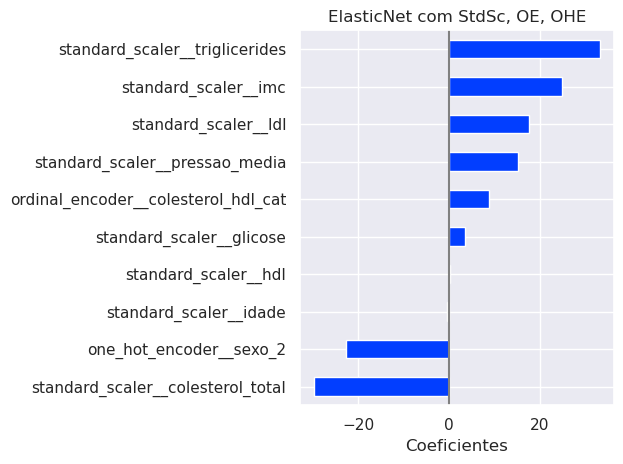

In [36]:
plot_coeficientes(coefs, "ElasticNet com StdSc, OE, OHE")

In [37]:
regressors = {
    "DummyRegressor": {
        "preprocessor": None,
        "regressor": DummyRegressor(strategy="mean"),
        "target_transformer": None,
    },
    
    "LinearRegression_pre_simples": {
        "preprocessor": preprocessamento_simples,
        "regressor": LinearRegression(),
        "target_transformer": None,
    },
    "ElasticNet_grid_search": {
        "preprocessor": grid_search.best_estimator_.regressor_["preprocessor"],
        "regressor": grid_search.best_estimator_.regressor_["reg"],
        "target_transformer": grid_search.best_estimator_.transformer_,
    },
}

In [38]:
resultados = {
    nome_modelo: treinar_e_validar_modelo_regressao(X, y, **regressor)
    for nome_modelo, regressor in regressors.items()
}

resultados

{'DummyRegressor': {'fit_time': array([0.00208807, 0.0018754 , 0.00106859, 0.00086117, 0.00076604]),
  'score_time': array([0.00121593, 0.00128412, 0.00104523, 0.00096583, 0.00101018]),
  'test_r2': array([-0.01196298, -0.02697753, -0.01530397, -0.00021233, -0.04231598]),
  'test_neg_mean_absolute_error': array([-64.00646147, -70.57793551, -59.82954545, -70.05392912,
         -65.42565485]),
  'test_neg_root_mean_squared_error': array([-73.22249284, -80.04318688, -74.33859714, -82.04745226,
         -76.3152967 ])},
 'LinearRegression_pre_simples': {'fit_time': array([0.0188911 , 0.0061605 , 0.00567245, 0.00477123, 0.00466537]),
  'score_time': array([0.0050261 , 0.0051775 , 0.00336289, 0.00303054, 0.00322366]),
  'test_r2': array([0.45229974, 0.57370343, 0.40683321, 0.58812556, 0.39131907]),
  'test_neg_mean_absolute_error': array([-42.98079751, -41.53071355, -46.70245302, -41.89567184,
         -47.42385601]),
  'test_neg_root_mean_squared_error': array([-53.86834947, -51.57031955, -

In [39]:
df_resultados = organiza_resultados(resultados)

df_resultados

,fit_time,score_time,test_r2,test_neg_mean_absolute_error,test_neg_root_mean_squared_error,model,time_seconds,MAE,RMSE
0,0.002088,0.001216,-0.011963,-64.006461,-73.222493,DummyRegressor,0.003304,64.006461,73.222493
1,0.001875,0.001284,-0.026978,-70.577936,-80.043187,DummyRegressor,0.003160,70.577936,80.043187
2,0.001069,0.001045,-0.015304,-59.829545,-74.338597,DummyRegressor,0.002114,59.829545,74.338597
3,0.000861,0.000966,-0.000212,-70.053929,-82.047452,DummyRegressor,0.001827,70.053929,82.047452
4,0.000766,0.001010,-0.042316,-65.425655,-76.315297,DummyRegressor,0.001776,65.425655,76.315297
5,0.018891,0.005026,0.452300,-42.980798,-53.868349,LinearRegression_pre_simples,0.023917,42.980798,53.868349
6,0.006160,0.005177,0.573703,-41.530714,-51.570320,LinearRegression_pre_simples,0.011338,41.530714,51.570320
7,0.005672,0.003363,0.406833,-46.702453,-56.820458,LinearRegression_pre_simples,0.009035,46.702453,56.820458
8,0.004771,0.003031,0.588126,-41.895672,-52.650369,LinearRegression_pre_simples,0.007802,41.895672,52.650369
9,0.004665,0.003224,0.391319,-47.423856,-58.318554,LinearRegression_pre_simples,0.007889,47.423856,58.318554


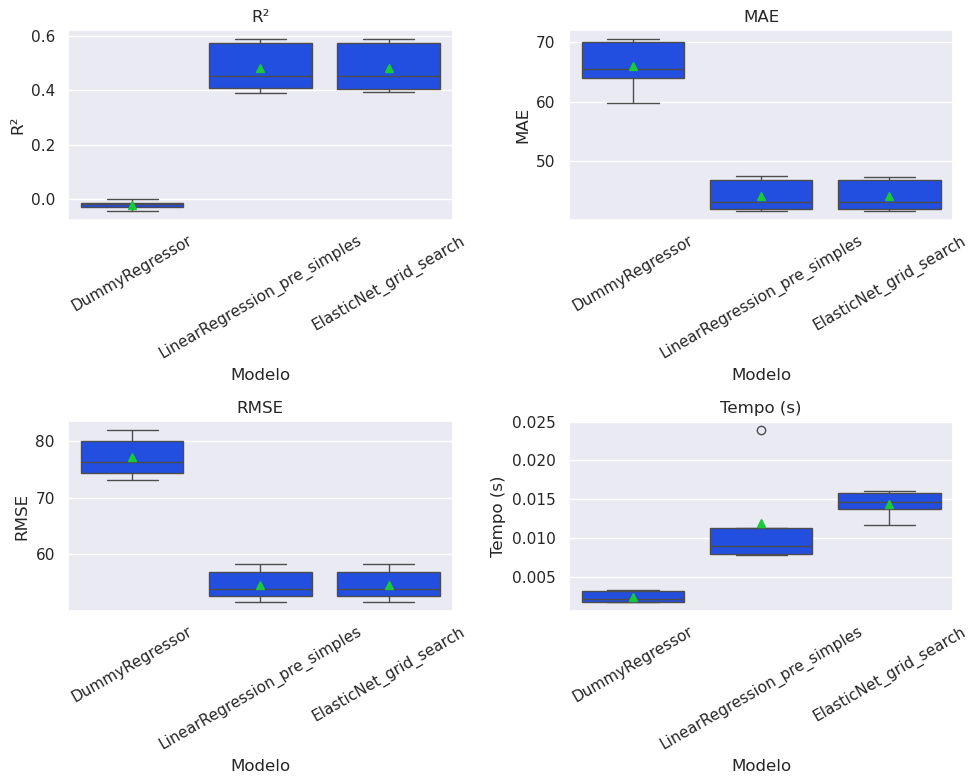

In [40]:
plot_comparar_metricas_modelos(df_resultados)